# CS 521 HW4, Bonus Research Question 1: certified training against universal adversarial perturbations

Brian Kim (bmkim2)

**Goal.** Improve CITRUS [Xu and Singh, 2024], the first certified training method against universal adversarial
perturbations (UAPs), to get a higher standard accuracy and a higher certified worst-case UAP accuracy on MNIST.

**Threat model** (as in CITRUS). A UAP is one perturbation $u$ with $\|u\|_\infty \le \epsilon$ that is added to every
input: the network sees $x + u$. We use the CITRUS MNIST setting $\epsilon = 0.1$, and the 3x50 fully connected network
of Problems 1 and 2. As in the UAP verifier of Zeng et al. [2023], $x + u$ is not clipped to $[0, 1]$; training, attacks
and certification all use this same threat model.

**Metric** (CITRUS, Appendix B). The test set is split into consecutive sets of $N = 5$ images. For each set we
compute the worst-case number of correct images under one shared $u$; the *certified average UAP accuracy* is the
sum over the sets divided by 10,000. CITRUS proves that this is a lower bound of the worst-case UAP accuracy of the
whole test set. We report

* `clean`: standard accuracy.
* `cert_indiv`: per-image certified accuracy (CROWN/IBP, $\ell_\infty$ ball of radius 0.1). This is the batch-size-1 version of the metric.
* `cert_uap`: certified average UAP accuracy (sets of 5), from our relational MILP verifier. It is sound: a lower bound.
* `attack_uap_sets`: the same quantity under our strongest UAP attack on each set: an upper bound. The true worst-case UAP accuracy of the sets is between `cert_uap` and `attack_uap_sets`.
* `attack_uap_global`: accuracy under one UAP for the whole test set (the classic UAP attack).

## Idea: G-CITRUS (group-UAP centered propagation boxes)

**Background.** The UAP training objective is $\min_\theta \max_{\|u\|\le\epsilon} \mathbb{E}_{(x,y)} \mathcal{L}(f(x+u), y)$
(CITRUS Eq. 4). CITRUS (Theorem 3.1) upper bounds it by $\mathcal{E}(k) = \mathbb{E}\big[\max_{u \in C(k)} \mathcal{L}(f(x+u),y)\big]$,
where $C(k)$ is the set of *$k$-common perturbations* (perturbations that are adversarial for $k$ inputs at the same time), and
$\mathcal{E}(\kappa^*) \le \dots \le \mathcal{E}(2) \le \mathcal{E}(1)$: the larger $k$, the tighter the bound and the less
regularization. $\mathcal{E}(1)$ is standard single-input certified training (IBP, SABR). CITRUS uses $\mathcal{E}(2)$ and
approximates $C(2)$ for image $x_i$ by the *other* images' adversarial perturbations $v_j$ (per-input PGD), with a small
SABR box around each: $\mathcal{L}_{CITRUS} = \sum_{j \ne i} \mathcal{L}_{IBP}(\mathcal{B}(x_i + v_j, \tau), y_i)$.

**Weak point of CITRUS.** $v_j$ maximizes the loss of image $j$ only. For image $i$ it is usually harmless (CITRUS Fig. 3: most
cross-input boxes "incur no regularization"), so most of the $N(N-1)$ propagated boxes are wasted. Also, no $v_j$ needs to be in
the common adversarial region of $x_i$ and $x_j$: the common perturbations that a UAP attacker actually uses are often not the
individually worst ones.

**Our change.** Find the common perturbation directly. For each group $G$ of $N=5$ images, we compute **one shared
perturbation** $u_G$ by PGD on a *saturated* group objective (a group UAP), and we propagate a small box around $x_i + u_G$
for every image of the group:

$$u_G \approx \arg\max_{\|u\|_\infty \le \epsilon - \tau} \sum_{i \in G} -\max\big(m_i(x_i + u), -\kappa\big), \qquad
m_i(x) = z_{y_i}(x) - \max_{j \ne y_i} z_j(x),$$

$$\mathcal{L}_{G\text{-}CITRUS} = \frac{1}{|B|}\sum_{G \subset B} \sum_{i \in G} \mathcal{L}_{IBP}\big(\mathcal{B}(x_i + u_G, \tau), y_i\big).$$

**Pseudocode.**
```
for epoch:
  for batch B (500 images = 100 groups of N = 5):
    eps_t = eps * schedule(t);  tau = lam * eps_t              # same warm-up / ramp as Problems 1-2
    for every group G in B (in parallel):
      u_G = random point in B(0, eps_t - tau)
      repeat 20 times:                                         # PGD on ONE shared u for the group
        loss_G = sum_{i in G} -max(margin_i(x_i + u_G), -kappa)
        u_G = clip(u_G + alpha * sign(grad_u loss_G), -(eps_t - tau), eps_t - tau)
    L = mean_{G, i in G} L_IBP(box(x_i + u_G, tau), y_i)       # N boxes per group (CITRUS: N(N-1))
    theta = Adam step on L
```

**Why each part should help.**

1. *Shared center $u_G$ (group UAP).* If $u_G$ fools $k \ge 2$ images of the group, it is a point of $C(k)$, so the boxes around
   it approximate the $k$-CP loss $\mathcal{E}(k)$, which is a tighter upper bound of the UAP objective than CITRUS's
   $\mathcal{E}(2)$ and SABR's $\mathcal{E}(1)$ (CITRUS Theorem 3.1). Tighter bound means less regularization, so higher clean
   accuracy, while still training on the perturbations that a UAP attacker can use. This is the same idea as universal
   adversarial training (UAT) [Shafahi et al., 2020], which updates one shared perturbation for a batch, but here combined
   with certified (box) training.
2. *Saturated objective ($\kappa$).* With a summed cross-entropy, the most vulnerable image dominates the gradient and $u_G$
   becomes that image's own adversarial perturbation: a same-input SABR box, which CITRUS shows (its Table 3) costs a lot of
   clean accuracy. Clipping each margin at $-\kappa$ (as in the confidence-$\kappa$ loss of Carlini and Wagner, 2017) stops
   the push on an image once it is fooled, so $u_G$ moves on to fool more images: a $k$-common perturbation with larger $k$.
3. *Small boxes ($\tau = \lambda\epsilon$).* A pure adversarial (point) loss gives almost no certificates (CITRUS Table 2: UAT
   has 1.5% certified UAP accuracy). The boxes keep the IBP certificate signal, as in SABR [Müller et al., 2023].
4. *Group size $N = 5$.* This is the CITRUS batch size and the size of the certification sets, so the training groups have the
   same structure as the sets that the verifier evaluates.
5. *Cost.* One shared PGD per group and $N$ boxes per group, instead of $N$ PGD runs and $N(N-1)$ boxes: G-CITRUS is cheaper than CITRUS.

**What is new.** CITRUS reuses per-input adversarial perturbations across inputs; UAT/CW-UAT [Shafahi et al., 2020; Benz et al.,
2021] use shared perturbations but only for empirical (point) adversarial training. G-CITRUS propagates certified boxes around
per-group shared perturbations, found with a saturated multi-image objective.

## Setup

In [1]:
import itertools
import json
import os
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
# !pip install scipy   # Colab has scipy
from scipy.optimize import Bounds, LinearConstraint, milp

torch.set_num_threads(2)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

EPS = 0.1          # l_inf radius of the universal perturbation (CITRUS, MNIST setting)
LAM = 0.5          # tau = LAM * eps: radius of the small propagation boxes
GROUP = 5          # images per group: CITRUS training batch size and size of each certification set
BATCH = 500        # 100 groups of 5 for each optimizer step
WARMUP, RAMP, EPOCHS = 1, 10, 20
LR = 4e-3
KAPPA = 1.0        # margin saturation of the group-UAP objective
CKPT_DIR = "checkpoints"

In [2]:
def load_mnist(train):
    ds = torchvision.datasets.MNIST("data", train=train, download=True)
    x = ds.data.float().div(255).unsqueeze(1)
    return x.to(device), ds.targets.to(device)


x_train, y_train = load_mnist(train=True)
x_test, y_test = load_mnist(train=False)


def make_model():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(784, 50), nn.ReLU(),
        nn.Linear(50, 50), nn.ReLU(),
        nn.Linear(50, 50), nn.ReLU(),
        nn.Linear(50, 10),
    ).to(device)


def linear_layers(model):
    return [m for m in model if isinstance(m, nn.Linear)]


def margins(logits, y):
    # z_y - max_{j != y} z_j  (negative = misclassified)
    zy = logits.gather(-1, y.unsqueeze(-1)).squeeze(-1)
    other = logits.scatter(-1, y.unsqueeze(-1), -float("inf")).max(-1).values
    return zy - other

## Bounds and adversaries

`ibp_margin_lower` is IBP with the last layer merged into the specification (as in Problems 1 and 2), on boxes that are not
clipped to $[0, 1]$. `pgd_delta` is the per-input PGD of SABR/CITRUS; `group_uap` is the shared group PGD of our method.

In [3]:
def ibp_margin_lower(model, c, r, y):
    # Lower bounds of z_y - z_j on the box [c - r, c + r] (the last layer is merged into the spec).
    # No clipping to [0, 1]: the UAP threat model is x + u with ||u||_inf <= eps (as in Zeng et al.).
    layers = linear_layers(model)
    c = c.flatten(1)
    first = layers[0]
    mid, rad = first(c), r * first.weight.abs().sum(1)
    l, u = mid - rad, mid + rad
    for layer in layers[1:-1]:
        l, u = F.relu(l), F.relu(u)
        mid, rad = layer((u + l) / 2), ((u - l) / 2) @ layer.weight.abs().t()
        l, u = mid - rad, mid + rad
    l, u = F.relu(l), F.relu(u)
    last = layers[-1]
    w = last.weight[y].unsqueeze(1) - last.weight.unsqueeze(0)
    b = last.bias[y].unsqueeze(1) - last.bias.unsqueeze(0)
    mid, rad = (u + l) / 2, (u - l) / 2
    return (w @ mid.unsqueeze(2)).squeeze(2) - (w.abs() @ rad.unsqueeze(2)).squeeze(2) + b


def ibp_loss(model, c, r, y):
    # L_IBP of Eq. 2 of CITRUS: CE of the negative margin lower bounds (entry y is 0).
    return F.cross_entropy(-ibp_margin_lower(model, c, r, y), y)

In [4]:
def pgd_delta(model, x, y, eps, steps):
    # Per-input PGD in the l_inf ball of radius eps (SABR / CITRUS centers).
    alpha = 2.5 * eps / steps
    delta = (torch.rand_like(x) * 2 - 1) * eps
    for _ in range(steps):
        delta.requires_grad_(True)
        g, = torch.autograd.grad(F.cross_entropy(model(x + delta), y), delta)
        delta = (delta.detach() + alpha * g.sign()).clamp(-eps, eps)
    return delta.detach()


def group_uap(model, x, y, eps, steps, objective="sat"):
    # One shared perturbation per group. x: (G, N, 1, 28, 28), y: (G, N). Returns u: (G, 1, 1, 28, 28).
    # objective "sat": maximize sum_i -max(m_i, -KAPPA): once an image is fooled by KAPPA its term is saturated,
    # so the perturbation moves on to fool more images of the group (a k-common perturbation).
    # objective "ce": maximize the summed cross-entropy (the easiest image dominates).
    G, N = x.shape[:2]
    alpha = 2.5 * eps / steps
    u = (torch.rand(G, 1, *x.shape[2:], device=x.device) * 2 - 1) * eps
    for _ in range(steps):
        u.requires_grad_(True)
        logits = model((x + u).flatten(0, 1)).view(G, N, -1)
        if objective == "sat":
            loss = -margins(logits, y).clamp(min=-KAPPA).sum()
        else:
            loss = F.cross_entropy(logits.flatten(0, 1), y.flatten(), reduction="sum")
        g, = torch.autograd.grad(loss, u)
        u = (u.detach() + alpha * g.sign()).clamp(-eps, eps)
    return u.detach()

## Training losses

All methods use the same schedule as Problems 1 and 2: standard training in the first epoch, then $\epsilon$ increases linearly
to 0.1 over 10 epochs; 20 epochs; Adam, learning rate $4\cdot10^{-3}$, divided by 10 after epoch 15; batches of 500 images
(100 groups of 5). SABR, CITRUS and G-CITRUS use $\lambda = \tau/\epsilon = 0.5$.

* `standard`: cross-entropy.
* `ibp`: IBP loss on the full ball.
* `sabr`: SABR (8 PGD steps, same-input box).
* `citrus`: CITRUS (20 PGD steps, the 20 cross-input boxes of each group of 5).
* `gcitrus`: our method.
* Ablations: `gcitrus_ce` (summed cross-entropy instead of the saturated group objective), `gcitrus_tau0` (no boxes:
  group-UAP adversarial training), `gcitrus_n2` (groups of 2 instead of 5).

In [5]:
def eps_scale(t):
    return 0.0 if t <= WARMUP else min((t - WARMUP) / RAMP, 1.0)


def standard_loss(model, x, y, t):
    return F.cross_entropy(model(x), y)


def ibp_train_loss(model, x, y, t):
    eps = EPS * eps_scale(t)
    if eps == 0:
        return standard_loss(model, x, y, t)
    return ibp_loss(model, x, eps, y)


def sabr_loss(model, x, y, t, lam=LAM):
    eps = EPS * eps_scale(t)
    if eps == 0:
        return standard_loss(model, x, y, t)
    tau = lam * eps
    delta = pgd_delta(model, x, y, eps - tau, steps=8)
    return ibp_loss(model, x + delta, tau, y)


def citrus_loss(model, x, y, t, lam=LAM, n=GROUP):
    # CITRUS (Xu and Singh, 2024): for each image i of a group, the IBP loss on the boxes B(x_i + v_j, tau), j != i,
    # where v_j is the PGD perturbation of image j (20 steps, in the ball of radius eps - tau).
    # Averaged over the N(N-1) pairs (CITRUS sums them; this only rescales the loss).
    eps = EPS * eps_scale(t)
    if eps == 0:
        return standard_loss(model, x, y, t)
    tau = lam * eps
    v = pgd_delta(model, x, y, eps - tau, steps=20)
    G = len(x) // n
    xg, vg, yg = x.view(G, n, *x.shape[1:]), v.view(G, n, *x.shape[1:]), y.view(G, n)
    pairs = torch.tensor([(i, j) for i in range(n) for j in range(n) if i != j], device=x.device)
    centers = xg[:, pairs[:, 0]] + vg[:, pairs[:, 1]]           # (G, n(n-1), 1, 28, 28)
    labels = yg[:, pairs[:, 0]]
    return ibp_loss(model, centers.flatten(0, 1), tau, labels.flatten())


def group_box_loss(model, x, y, t, lam=LAM, n=GROUP, objective="sat"):
    # Our method (G-CITRUS): one shared group-UAP u_G per group of n images, found by PGD on the saturated
    # group objective in the ball of radius eps - tau; then the IBP loss on B(x_i + u_G, tau) for every image.
    # With lam = 0 this is UAT-style group adversarial training (no boxes).
    eps = EPS * eps_scale(t)
    if eps == 0:
        return standard_loss(model, x, y, t)
    tau = lam * eps
    G = len(x) // n
    xg, yg = x.view(G, n, *x.shape[1:]), y.view(G, n)
    u = group_uap(model, xg, yg, eps - tau, steps=20, objective=objective)
    centers = (xg + u).flatten(0, 1)
    if tau == 0:
        return F.cross_entropy(model(centers), y)
    return ibp_loss(model, centers, tau, y)

In [6]:
def train(model, loss_fn, epochs=EPOCHS, lr=LR, batch_size=BATCH, seed=0, verbose=True):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.MultiStepLR(opt, milestones=[15], gamma=0.1)
    n_batches = len(x_train) // batch_size
    epoch_times = []
    for epoch in range(epochs):
        model.train()
        start, total = time.time(), 0.0
        idx = torch.randperm(len(x_train), device=device)
        for i in range(n_batches):
            j = idx[i * batch_size:(i + 1) * batch_size]
            loss = loss_fn(model, x_train[j], y_train[j], epoch + i / n_batches)
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item()
        sched.step()
        epoch_times.append(time.time() - start)
        if verbose:
            print(f"epoch {epoch + 1:2d}  loss {total / n_batches:.4f}  time {epoch_times[-1]:.1f} s", flush=True)
    return epoch_times


LOSSES = {
    "standard": standard_loss,
    "ibp": ibp_train_loss,
    "sabr": sabr_loss,
    "citrus": citrus_loss,
    "gcitrus": group_box_loss,                                                  # our method
    "gcitrus_ce": lambda m, x, y, t: group_box_loss(m, x, y, t, objective="ce"),  # ablation: CE group objective
    "gcitrus_tau0": lambda m, x, y, t: group_box_loss(m, x, y, t, lam=0.0),       # ablation: no boxes
    "gcitrus_n2": lambda m, x, y, t: group_box_loss(m, x, y, t, n=2),             # ablation: groups of 2
}
for _lam in [0.3, 0.7]:                                                           # trade-off curves (lambda sweep)
    LOSSES[f"citrus_l{_lam}"] = lambda m, x, y, t, lam=_lam: citrus_loss(m, x, y, t, lam=lam)
    LOSSES[f"gcitrus_l{_lam}"] = lambda m, x, y, t, lam=_lam: group_box_loss(m, x, y, t, lam=lam)


def get_model(name, seed=0, verbose=True):
    # Trains the model, or loads it from CKPT_DIR if it was trained before.
    os.makedirs(CKPT_DIR, exist_ok=True)
    path = os.path.join(CKPT_DIR, f"{name}_s{seed}.pt")
    model = make_model()
    if os.path.exists(path):
        ck = torch.load(path, map_location=device)
        model.load_state_dict(ck["state"])
        return model, ck["epoch_times"]
    torch.manual_seed(seed)
    model = make_model()
    times = train(model, LOSSES[name], seed=seed, verbose=verbose)
    torch.save({"state": model.state_dict(), "epoch_times": times}, path)
    return model, times

## Certification and attacks

**Certified worst-case UAP accuracy of a set (sound).** For each test image, CROWN [Zhang et al., 2018] (with intermediate bounds
the tighter of CROWN and IBP) gives linear lower bounds $z_y - z_j \ge a_{ij}^\top x' + c_{ij}$ that hold on the whole box
$\|x' - x_i\|_\infty \le \epsilon$. An image whose lower bounds are all positive is certified alone. For the other correctly
classified images of the set, image $i$ can only be misclassified at $x_i + u$ if $a_{ij}^\top (x_i + u) + c_{ij} \le 0$ for
some $j$. The MILP (a variant of Zeng et al. [2023]; solved exactly with HiGHS through `scipy.optimize.milp`)

$$\max_{u, s, z} \sum_i z_i \quad \text{s.t.}\quad a_{ij}^\top u + M_{ij} s_{ij} \le M_{ij} - a_{ij}^\top x_i - c_{ij},\quad
z_i \le \sum_j s_{ij}, \quad \|u\|_\infty \le \epsilon, \quad s, z \in \{0,1\}$$

bounds the number of images that **one shared** $u$ can misclassify ($M_{ij}$ is the maximum of the linear bound on the box).
The certified count of the set is (correct images) minus this bound. If the solver hits the time limit, we use its dual bound, so
the result stays sound. This is where the UAP metric gains over per-image certification: two images that are each
attackable alone may not be attackable by the same $u$.

**Attack (upper bound).** For each set and each of the 31 non-empty subsets of its 5 images, PGD (50 steps, 2 restarts) on one
shared $u$ with the saturated margin loss on that subset; the MILP solutions are also tried. A set's count is its strongest
attack. We also run a classic dataset-level UAP attack: one $u$ for all 10,000 test images.

In [7]:
def _relu_relaxation(l, u):
    active, unstable = l >= 0, (l < 0) & (u > 0)
    s = torch.where(active, torch.ones_like(l), torch.zeros_like(l))
    s = torch.where(unstable, u / (u - l).clamp(min=1e-12), s)
    c = torch.where(unstable, -s * l, torch.zeros_like(l))
    alpha = torch.where(active | (unstable & (u > -l)), torch.ones_like(l), torch.zeros_like(l))
    return alpha, s, c


def _backward(A, layers, bounds):
    # Linear lower bound A' x' + const of A z (z = output of layers[-1]) that holds for all x' with the given
    # intermediate bounds. Returns (A' (B, m, 784), const (B, m)).
    const = torch.zeros(A.shape[:2], device=A.device)
    for i in range(len(layers) - 1, -1, -1):
        const = const + A @ layers[i].bias
        A = A @ layers[i].weight
        if i > 0:
            alpha, s, c = _relu_relaxation(*bounds[i - 1])
            a_pos, a_neg = A.clamp(min=0), A.clamp(max=0)
            const = const + (a_neg * c.unsqueeze(1)).sum(2)
            A = a_pos * alpha.unsqueeze(1) + a_neg * s.unsqueeze(1)
    return A, const


def _concretize(A, const, x, eps):
    return const + (A @ x.unsqueeze(2)).squeeze(2) - eps * A.abs().sum(2)


@torch.no_grad()
def linear_margin_bounds(model, x, y, eps):
    # CROWN linear bounds of the margins on the box [x - eps, x + eps] (no clipping).
    # Returns A (B, 10, 784), c (B, 10) with z_y - z_j >= A_j x' + c_j for all x' in the box, and the
    # concrete lower bounds max(CROWN, IBP) (B, 10). The intermediate bounds are the tighter of IBP and CROWN.
    layers = linear_layers(model)
    x = x.flatten(1)
    bounds, l, u = [], None, None
    for k in range(len(layers) - 1):
        lay = layers[k]
        if k == 0:
            mid, rad = lay(x), eps * lay.weight.abs().sum(1)
            il, iu = mid - rad, mid + rad
        else:
            pl, pu = F.relu(l), F.relu(u)
            mid, rad = lay((pu + pl) / 2), ((pu - pl) / 2) @ lay.weight.abs().t()
            il, iu = mid - rad, mid + rad
        eye = torch.eye(lay.out_features, device=x.device).expand(len(x), -1, -1)
        lo = _concretize(*_backward(eye, layers[:k + 1], bounds), x, eps)
        hi = -_concretize(*_backward(-eye, layers[:k + 1], bounds), x, eps)
        l, u = torch.maximum(lo, il), torch.minimum(hi, iu)
        bounds.append((l, u))
    eye = torch.eye(10, device=x.device)
    spec = eye[y].unsqueeze(1) - eye.unsqueeze(0)
    A, c = _backward(spec, layers, bounds)
    lower = torch.maximum(_concretize(A, c, x, eps), ibp_margin_lower(model, x, eps, y))
    return A, c, lower

In [8]:
def max_fooled_milp(A, c, lower, x, eps, time_limit=30.0):
    # Upper bound on the number of images of one set that one shared u (||u||_inf <= eps) can misclassify.
    # A: (k, 10, 784), c, lower: (k, 10), x: (k, 784) for the k images of the set that are not certified alone.
    # Image i is misclassified only if some margin j is <= 0, which needs A_ij (x_i + u) + c_ij <= 0.
    # MILP: binaries s_ij (image i is fooled through class j), z_i <= sum_j s_ij, maximize sum_i z_i.
    k, d = len(A), x.shape[1]
    rows, cols = [], []
    for i in range(k):
        for j in range(10):
            if lower[i, j] <= 0:          # class j is still possible for image i
                rows.append(i); cols.append(j)
    m = len(rows)
    nv = d + m + k                        # u, s, z
    Acon = np.zeros((m + k, nv)); lb = np.full(m + k, -np.inf); ub = np.zeros(m + k)
    for r, (i, j) in enumerate(zip(rows, cols)):
        a = A[i, j]
        b = float(a @ x[i] + c[i, j])
        M = max(b + eps * float(a.abs().sum()), 0.0)          # max of a (x_i + u) + c over the box
        Acon[r, :d] = a.numpy()
        Acon[r, d + r] = M                                    # a u + M s_ij <= M - b
        ub[r] = M - b
    for i in range(k):
        Acon[m + i, d + m + i] = 1.0                          # z_i - sum_j s_ij <= 0
        for r in range(m):
            if rows[r] == i:
                Acon[m + i, d + r] = -1.0
    obj = np.zeros(nv); obj[d + m:] = -1.0
    integrality = np.zeros(nv); integrality[d:] = 1
    lo = np.concatenate([np.full(d, -eps), np.zeros(m + k)])
    hi = np.concatenate([np.full(d, eps), np.ones(m + k)])
    res = milp(obj, constraints=LinearConstraint(Acon, lb, ub), integrality=integrality, bounds=Bounds(lo, hi),
               options={"time_limit": time_limit, "mip_rel_gap": 0.0})
    if res.status == 0:
        return int(round(-res.fun)), torch.tensor(res.x[:d], dtype=torch.float32), True
    dual = getattr(res, "mip_dual_bound", None)                 # time limit: use the solver's bound (sound)
    bound = k if dual is None or not np.isfinite(dual) else min(k, int(np.floor(-dual + 1e-6)))
    u = torch.tensor(res.x[:d], dtype=torch.float32) if res.x is not None else None
    return bound, u, False


@torch.no_grad()
def certify_sets(model, x, y, eps=EPS, n=GROUP, chunk=500):
    # Certified worst-case UAP accuracy, averaged over consecutive sets of n test images (CITRUS, App. B).
    # For each set: images that are misclassified count as wrong, images that CROWN/IBP certify alone count as
    # correct, and the MILP bounds how many of the other images one shared perturbation can misclassify.
    model.eval()
    correct_lb, indiv, n_milp, n_timeout, milp_us = 0, 0, 0, 0, {}
    for s0 in range(0, len(x), chunk):
        xb, yb = x[s0:s0 + chunk], y[s0:s0 + chunk]
        clean = model(xb).argmax(1) == yb
        A, c, lower = linear_margin_bounds(model, xb, yb, eps)
        lower[torch.arange(len(yb)), yb] = float("inf")
        cert = clean & (lower.min(1).values > 0)
        indiv += cert.sum().item()
        xf = xb.flatten(1)
        for g in range(0, len(xb), n):
            idx = torch.arange(g, min(g + n, len(xb)))
            unc = idx[clean[idx] & ~cert[idx]]
            fooled = len(unc)
            if len(unc) >= 2:
                fooled, u, ok = max_fooled_milp(A[unc], c[unc], lower[unc], xf[unc], eps)
                n_milp += 1; n_timeout += not ok
                if u is not None:
                    milp_us[s0 + g] = u
            correct_lb += clean[idx].sum().item() - fooled
    N = len(x)
    return {"cert_uap": 100 * correct_lb / N, "cert_indiv": 100 * indiv / N, "n_milp": n_milp,
            "n_timeout": n_timeout}, milp_us

In [9]:
SUBSETS = torch.tensor([m for m in itertools.product([0, 1], repeat=GROUP) if any(m)], dtype=torch.float32)


def attack_sets(model, x, y, eps=EPS, n=GROUP, steps=50, restarts=2, chunk=100, extra_us=None):
    # Empirical worst-case UAP accuracy for the same sets of n images (an upper bound of the true value).
    # For each set, PGD on one shared u for each of the 2^n - 1 subsets (saturated margin loss on the subset),
    # with random restarts; the MILP solutions (extra_us) are also tried. A set's count is its best attack.
    model.eval()
    masks = SUBSETS.to(x.device)
    K = len(masks)
    S = len(x) // n
    xs, ys = x[:S * n].view(S, n, -1), y[:S * n].view(S, n)
    best = torch.zeros(S, device=x.device)
    alpha = 2.5 * eps / steps
    for s0 in range(0, S, chunk):
        xc, yc = xs[s0:s0 + chunk], ys[s0:s0 + chunk]
        C = len(xc)
        yk = yc[:, None].expand(C, K, n)
        for _ in range(restarts):
            u = (torch.rand(C, K, 1, xc.shape[-1], device=x.device) * 2 - 1) * eps
            for _ in range(steps):
                u.requires_grad_(True)
                logits = model((xc[:, None] + u).reshape(-1, xc.shape[-1])).view(C, K, n, -1)
                loss = -(margins(logits, yk).clamp(min=-KAPPA) * masks).sum()
                g, = torch.autograd.grad(loss, u)
                u = (u.detach() + alpha * g.sign()).clamp(-eps, eps)
            with torch.no_grad():
                logits = model((xc[:, None] + u).reshape(-1, xc.shape[-1])).view(C, K, n, -1)
                fooled = (logits.argmax(-1) != yk).sum(-1).float().max(1).values
                best[s0:s0 + C] = torch.maximum(best[s0:s0 + C], fooled)
    with torch.no_grad():
        for i, u in (extra_us or {}).items():
            s = i // n
            if s < S:
                fooled = (model(xs[s] + u.to(x.device)).argmax(-1) != ys[s]).sum().float()
                best[s] = torch.maximum(best[s], fooled)
    return 100 * (1 - best.sum().item() / (S * n))


def dataset_uap(model, x, y, eps=EPS, epochs=5, batch_size=1000, steps_per_batch=5):
    # One universal perturbation for the whole test set (sign-gradient ascent on the saturated loss over
    # mini-batches, 3 random restarts). Returns the accuracy under the best perturbation found.
    model.eval()
    best_acc, best_u = 100.0, None
    for r in range(3):
        u = ((torch.rand(1, *x.shape[1:], device=x.device) * 2 - 1) * eps) if r else torch.zeros(1, *x.shape[1:], device=x.device)
        for _ in range(epochs):
            for s0 in range(0, len(x), batch_size):
                xb, yb = x[s0:s0 + batch_size], y[s0:s0 + batch_size]
                for _ in range(steps_per_batch):
                    u.requires_grad_(True)
                    loss = -margins(model(xb + u), yb).clamp(min=-KAPPA).sum()
                    g, = torch.autograd.grad(loss, u)
                    u = (u.detach() + 0.005 * g.sign()).clamp(-eps, eps)
        with torch.no_grad():
            acc = 100 * (model(x + u).argmax(1) == y).float().mean().item()
        if acc < best_acc:
            best_acc, best_u = acc, u
    return best_acc, best_u

In [10]:
RESULTS_PATH = "results.json"


def evaluate(model, name, n_test=10000, use_cache=True):
    cache = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else {}
    if use_cache and name in cache:
        return cache[name]
    x, y = x_test[:n_test], y_test[:n_test]
    t0 = time.time()
    with torch.no_grad():
        clean = 100 * (model(x).argmax(1) == y).float().mean().item()
    cert, milp_us = certify_sets(model, x, y)
    t1 = time.time()
    att = attack_sets(model, x, y, extra_us=milp_us)
    t2 = time.time()
    uap, _ = dataset_uap(model, x, y)
    res = {"name": name, "clean": clean, **cert, "attack_uap_sets": att, "attack_uap_global": uap,
           "cert_time": t1 - t0, "attack_time": t2 - t1}
    cache = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else {}
    cache[name] = res
    json.dump(cache, open(RESULTS_PATH, "w"), indent=1)
    return res

In [11]:
def box_diagnostics(model, n_img=2000, lam=LAM, n=GROUP, seed=0):
    # For training images and the full eps: the IBP loss of each kind of propagation box, and how often its center
    # is adversarial (at the point). SI = same-input SABR box, CI = CITRUS cross-input boxes, G = group-UAP box.
    torch.manual_seed(seed)
    model.eval()
    x, y = x_train[:n_img], y_train[:n_img]
    eps, tau = EPS, lam * EPS
    G = n_img // n
    xg, yg = x.view(G, n, *x.shape[1:]), y.view(G, n)
    v = pgd_delta(model, x, y, eps - tau, steps=20)
    vg = v.view(G, n, *x.shape[1:])
    u = group_uap(model, xg, yg, eps - tau, steps=20)
    pairs = torch.tensor([(i, j) for i in range(n) for j in range(n) if i != j])
    out = {}
    with torch.no_grad():
        def box_loss(c, lab):
            return F.cross_entropy(-ibp_margin_lower(model, c, tau, lab), lab, reduction="none")
        def adv(c, lab):
            return (model(c).argmax(1) != lab).float()
        si = box_loss(x + v, y)
        ci = box_loss((xg[:, pairs[:, 0]] + vg[:, pairs[:, 1]]).flatten(0, 1), yg[:, pairs[:, 0]].flatten())
        ci = ci.view(G, n, n - 1)
        gb = box_loss((xg + u).flatten(0, 1), y)
        out["loss_SI"] = si.mean().item()
        out["loss_CI_mean"] = ci.mean().item()
        out["loss_CI_max_over_j"] = ci.max(2).values.mean().item()
        out["frac_CI_boxes_loss<0.01"] = (ci < 0.01).float().mean().item()
        out["loss_G"] = gb.mean().item()
        out["frac_G_boxes_loss<0.01"] = (gb < 0.01).float().mean().item()
        out["adv_SI_center"] = adv(x + v, y).mean().item()
        out["adv_CI_center"] = adv((xg[:, pairs[:, 0]] + vg[:, pairs[:, 1]]).flatten(0, 1),
                                   yg[:, pairs[:, 0]].flatten()).mean().item()
        out["adv_G_center"] = adv((xg + u).flatten(0, 1), y).mean().item()
        fooled = adv((xg + u).flatten(0, 1), y).view(G, n).sum(1)
        out["groups_uG_fools>=2"] = (fooled >= 2).float().mean().item()
    return out

## Train and evaluate

`get_model` trains the model, or loads it from `checkpoints/` if it exists; `evaluate` caches the results in
`results.json`. Without these files (for example on Colab), this cell trains and evaluates every model (CPU: about 2 to 4
minutes of training per model).

In [12]:
RUNS = [("standard", 0), ("ibp", 0), ("ibp", 1), ("sabr", 0), ("sabr", 1), ("citrus", 0), ("citrus", 1),
        ("gcitrus", 0), ("gcitrus", 1), ("gcitrus_n2", 0), ("gcitrus_n2", 1),
        ("gcitrus_ce", 0), ("gcitrus_tau0", 0),
        ("citrus_l0.3", 0), ("citrus_l0.7", 0), ("gcitrus_l0.3", 0), ("gcitrus_l0.7", 0)]
rows = []
for name, seed in RUNS:
    model, times = get_model(name, seed, verbose=False)   # loads the checkpoint if it exists, otherwise trains
    rows.append(dict(evaluate(model, f"{name}_s{seed}"), method=name, seed=seed, time_per_epoch=np.mean(times)))

## Results

In [13]:
import pandas as pd

df = pd.DataFrame(rows)
cols = ["clean", "cert_indiv", "cert_uap", "attack_uap_sets", "attack_uap_global", "time_per_epoch"]
pd.set_option("display.precision", 2)
print("Per run:")
display(df[["method", "seed"] + cols + ["n_milp", "n_timeout"]])
main = ["standard", "ibp", "sabr", "citrus", "gcitrus", "gcitrus_n2"]
print("Mean over seeds:")
display(df[df.method.isin(main)].groupby("method", sort=False)[cols].mean())

Per run:


,method,seed,clean,cert_indiv,cert_uap,attack_uap_sets,attack_uap_global,time_per_epoch,n_milp,n_timeout
0,standard,0,97.50,0.00,0.00,0.31,17.68,0.30,2000,0
1,ibp,0,87.70,74.24,74.28,76.57,85.63,1.03,288,0
2,ibp,1,87.65,74.13,74.15,76.60,85.66,1.02,286,0
3,sabr,0,91.94,67.07,67.20,80.13,90.23,4.57,733,0
4,sabr,1,92.05,68.10,68.24,79.42,90.15,3.73,677,0
5,citrus,0,94.27,59.52,59.97,76.78,92.17,7.74,1097,0
6,citrus,1,94.07,58.55,59.13,77.62,91.98,8.60,1137,0
7,gcitrus,0,93.75,63.67,64.01,78.09,92.76,4.38,947,0
8,gcitrus,1,93.44,64.33,64.88,79.52,91.84,3.78,891,0
9,gcitrus_n2,0,93.33,68.11,68.27,79.78,91.77,2.64,754,0


Mean over seeds:


,clean,cert_indiv,cert_uap,attack_uap_sets,attack_uap_global,time_per_epoch
method,,,,,,
standard,97.50,0.00,0.00,0.31,17.68,0.30
ibp,87.67,74.19,74.22,76.59,85.64,1.02
sabr,91.99,67.58,67.72,79.78,90.19,4.15
citrus,94.17,59.03,59.55,77.20,92.07,8.17
gcitrus,93.60,64.00,64.44,78.81,92.30,4.08
gcitrus_n2,93.19,66.62,66.81,79.50,91.73,2.41


**Main comparison** (λ = 0.5, mean of 2 seeds; ε = 0.1; test set of 10,000 images, sets of 5):

| method | clean | cert. indiv. | **cert. UAP** (lower bound) | attack UAP, sets (upper bound) | attack UAP, global | time/epoch (s) |
|---|---|---|---|---|---|---|
| standard | 97.50 | 0.00 | 0.00 | 0.31 | 17.68 | 0.3 |
| IBP | 87.67 | 74.18 | 74.22 | 76.59 | 85.64 | 1.0 |
| SABR | 91.99 | 67.58 | 67.72 | 79.78 | 90.19 | 4.2 |
| CITRUS | **94.17** | 59.04 | 59.55 | 77.20 | 92.07 | 8.2 |
| **G-CITRUS (ours, N=5)** | 93.60 | 64.00 | **64.44** | 78.81 | 92.30 | 4.1 |
| **G-CITRUS (ours, N=2)** | 93.19 | 66.62 | **66.82** | 79.50 | 91.73 | 2.4 |

(`standard` has one seed. The times are on a shared 2-thread CPU, so they are noisy; the λ-sweep runs below ran later
with less load. Compared in the same period, G-CITRUS is 1.5x to 2x faster per epoch than CITRUS.)

**Trade-off curves** (λ ∈ {0.3, 0.5, 0.7}; λ = 0.5 is the mean of 2 seeds, the others are seed 0):

| λ | CITRUS clean / cert. UAP | G-CITRUS clean / cert. UAP |
|---|---|---|
| 0.3 | 95.68 / 38.61 | 94.59 / 46.80 |
| 0.5 | 94.17 / 59.55 | 93.60 / 64.44 |
| 0.7 | 92.26 / 69.69 | 91.81 / 72.83 |

At the same λ, G-CITRUS has 0.4 to 1.1 points lower clean accuracy and 3.1 to 8.2 points higher certified UAP accuracy.
The fair comparison is at the same clean accuracy, on CITRUS's curve (linear interpolation between its λ points):

* G-CITRUS λ=0.5 (93.60 clean): CITRUS at 93.60 clean gives about 62.6 certified; G-CITRUS gives 64.4 (**+1.8**).
* G-CITRUS N=2 (93.19 clean): CITRUS gives about 64.8; G-CITRUS gives 66.8 (**+2.0**).
* G-CITRUS λ=0.7 (91.81 clean): CITRUS (extrapolated) gives about 72.1; G-CITRUS gives 72.8 (+0.7).
* G-CITRUS λ=0.3 (94.59 clean): CITRUS gives about 53.6; G-CITRUS gives 46.8 (**−6.8**).

Against the other baselines: G-CITRUS N=2 has +1.2 clean and −0.9 certified compared with SABR; G-CITRUS λ=0.7 has
−0.2 clean and **+5.1** certified compared with SABR, and +4.1 clean and −1.4 certified compared with IBP.

## Ablation

Each ablation changes one part of G-CITRUS (seed 0; λ = 0.5). The λ sweep is also shown. `box_diagnostics` measures the loss of each kind of box on each trained model.

,clean,cert_indiv,cert_uap,attack_uap_sets,attack_uap_global,time_per_epoch
method,,,,,,
gcitrus,93.75,63.67,64.01,78.09,92.76,4.38
gcitrus_ce,92.68,66.13,66.35,79.08,91.56,2.41
gcitrus_tau0,97.85,0.01,0.01,76.10,97.01,2.28
gcitrus_n2,93.33,68.11,68.27,79.78,91.77,2.64
gcitrus_l0.3,94.59,45.30,46.80,77.01,93.67,2.04
gcitrus_l0.7,91.81,72.76,72.83,79.02,89.91,2.30
citrus_l0.3,95.68,37.44,38.61,74.37,93.63,4.18
citrus,94.27,59.52,59.97,76.78,92.17,7.74
citrus_l0.7,92.26,69.54,69.69,77.61,89.40,3.41


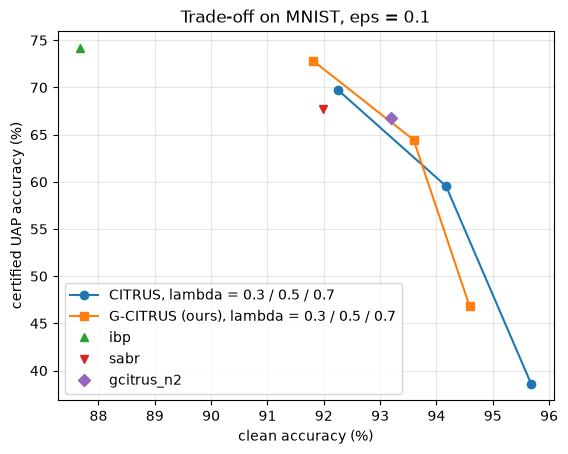

,loss_SI,loss_CI_mean,loss_CI_max_over_j,frac_CI_boxes_loss<0.01,loss_G,frac_G_boxes_loss<0.01,adv_SI_center,adv_CI_center,adv_G_center,groups_uG_fools>=2
sabr,0.71,0.54,0.65,0.04,0.62,0.01,0.12,0.08,0.12,0.09
citrus,0.97,0.56,0.73,0.13,0.74,0.05,0.12,0.06,0.10,0.07
gcitrus,0.88,0.57,0.72,0.11,0.68,0.04,0.13,0.07,0.11,0.09
gcitrus_n2,0.79,0.55,0.66,0.10,0.63,0.05,0.12,0.08,0.10,0.06


In [14]:
abl = ["gcitrus", "gcitrus_ce", "gcitrus_tau0", "gcitrus_n2", "gcitrus_l0.3", "gcitrus_l0.7", "citrus_l0.3", "citrus",
       "citrus_l0.7", "sabr"]
display(df[df.method.isin(abl) & (df.seed == 0)].set_index("method").loc[abl, cols])

import matplotlib.pyplot as plt
m = df.groupby("method")[["clean", "cert_uap"]].mean()
for fam, names, mk in [("CITRUS", ["citrus_l0.3", "citrus", "citrus_l0.7"], "o-"),
                       ("G-CITRUS (ours)", ["gcitrus_l0.3", "gcitrus", "gcitrus_l0.7"], "s-")]:
    plt.plot(m.loc[names, "clean"], m.loc[names, "cert_uap"], mk, label=f"{fam}, lambda = 0.3 / 0.5 / 0.7")
for name, mk in [("ibp", "^"), ("sabr", "v"), ("gcitrus_n2", "D")]:
    plt.plot(m.loc[name, "clean"], m.loc[name, "cert_uap"], mk, label=name)
plt.xlabel("clean accuracy (%)"); plt.ylabel("certified UAP accuracy (%)"); plt.grid(alpha=0.3); plt.legend()
plt.title("Trade-off on MNIST, eps = 0.1"); plt.show()

diag = {name: box_diagnostics(get_model(name, 0, verbose=False)[0]) for name in ["sabr", "citrus", "gcitrus", "gcitrus_n2"]}
display(pd.DataFrame(diag).T)

## Analysis

**Does it work?** Partly. G-CITRUS does not dominate CITRUS at the same hyperparameters: it moves along the trade-off
(about −0.6 clean, +4.9 certified UAP accuracy at λ = 0.5). On the trade-off curve, it is better than CITRUS in the
medium/high-certification range (+0.7 to +2.0 points of certified UAP accuracy at the same clean accuracy, for
λ ≥ 0.5 and for N = 2), and it trains 1.5x to 2x faster. In the high-clean range (λ = 0.3) it is clearly worse (−6.8).
The gains are of the same size as the seed-to-seed spread (G-CITRUS N=2: 68.3 and 65.4 certified for the two seeds), so
with 1 to 2 seeds the improvement is suggestive, not conclusive. We did not get "higher clean *and* higher certified
accuracy than CITRUS" at one setting.

**Comparison with single-input certified training.** G-CITRUS does not dominate SABR either: SABR reaches 91.99 / 67.72 (clean / certified UAP) and G-CITRUS with N = 2 reaches 93.19 / 66.82, so the two lie on the same trade-off curve. Plain IBP has the highest certified UAP accuracy of all methods (74.22) at a much lower clean accuracy (87.67). With this small network and verifier, the cross-input structure of the training does not give a clear gain over single-input certified training; the benefit of G-CITRUS over CITRUS is mainly speed and a better trade-off at λ ≥ 0.5.

**Why the result looks like this (diagnostics).** `box_diagnostics` measures, on 2,000 training images and the full ε,
the IBP loss of each kind of box and how often its center is adversarial:

* The group UAP $u_G$ fools at least 2 images of a group in only 7-9% of the groups (all models), and its center is
  adversarial for about 10-11% of the images, almost as often as the same-input SABR center (12%) and more than the
  cross-input CITRUS centers (6-8%). So $u_G$ is usually an adversarial perturbation for **one** image of the group that
  is reused by the other images; it is rarely a true $k$-common perturbation with $k \ge 2$. Part 1 of our justification
  (training on $C(k)$ with large $k$) holds only for a small fraction of the groups.
* As a result, a G-CITRUS group behaves like about one same-input box plus four cross-input boxes. Its box loss (0.62-0.74)
  is between the CITRUS cross-input loss (0.54-0.57) and the same-input SABR loss (0.71-0.97) on every model, and its
  results are between CITRUS and SABR: more regularization than CITRUS (lower clean accuracy) and more certification.
* Our hypothesis that most CITRUS cross-input boxes are wasted is only weakly true here: only 4-13% of them have a
  loss below 0.01. For this small network, most of the box loss comes from the looseness of IBP, not from whether the
  center is adversarial. This also explains why moving the centers changes the results by only a few points.

**Ablation.**

* *Saturated objective → summed cross-entropy* (`gcitrus_ce`): 92.68 clean / 66.35 certified, between G-CITRUS
  (93.75 / 64.01, seed 0) and SABR (91.99 / 67.72). As predicted in part 2 of the justification, without the saturation
  the most vulnerable image dominates and $u_G$ becomes a same-input perturbation, so the method moves toward SABR
  (more regularization, less clean accuracy). The saturation is what makes G-CITRUS a different trade-off point.
* *No boxes* (`gcitrus_tau0`, τ = 0: group-UAP adversarial training, similar to UAT): 97.85 clean, **0.01%
  certified**, but 76.1% under our set-UAP attack and 97.0% under the global UAP. The empirical UAP robustness is high,
  but nothing can be certified. The boxes (part 3) are necessary, as CITRUS's Table 2 also shows for UAT.
* *Groups of 2 instead of 5* (`gcitrus_n2`): 93.19 / 66.82 (2 seeds), a better trade-off point than N = 5 and faster.
  With 2 images, $u_G$ is more often adversarial for the image that matters, so it is closer to SABR, but it still keeps
  1.2 points more clean accuracy than SABR.

**Certified vs. attack accuracy and the role of the UAP threat model.** In every row the certified UAP accuracy is below
the attack accuracy, so the results are consistent (a sound lower bound and an upper bound). The relational MILP adds at
most 1.5 points over per-image certification (`cert_uap` vs `cert_indiv`), the most for the low-λ models, which have
many uncertified images. With CROWN linear bounds, two uncertified images of the same set can almost always be
"fooled" by the same $u$ in the relaxation. So for this network the certified UAP accuracy is mostly per-image
certified accuracy, and the potential benefit of the weaker UAP threat model shows up in the clean accuracy (CITRUS
and G-CITRUS: 93-94% vs IBP 88%), not in the certificates. The gap between certified (59-74%) and attack (76-80%) accuracy
is large for the cross-input methods (CITRUS: 17.7 points, G-CITRUS: 14.4), and small for IBP (2.4): the cross-input
methods are less regularized, so their bounds are looser. A tighter relational verifier (RACoon [Banerjee and Singh, 2024],
as used by CITRUS) could close part of this gap, especially for CITRUS and G-CITRUS.

**Limitations.** Small 3x50 network and 20 epochs on CPU (the CITRUS paper uses CNN7 and much longer training, so
the absolute numbers are not comparable to its Table 1); 1 to 2 seeds; no clipping of $x + u$ to $[0, 1]$; our verifier is
a CROWN + MILP variant of Zeng et al., not RACoon.

## References

* C. Xu and G. Singh. Cross-input certified training for universal perturbations (CITRUS). ECCV 2024, arXiv:2405.09176.
* D. Banerjee and G. Singh. Relational DNN verification with cross executional bound refinement (RACoon). ICML 2024.
* M. Müller, F. Eckert, M. Fischer, M. Vechev. Certified training: small boxes are all you need (SABR). ICLR 2023.
* S. Gowal et al. On the effectiveness of interval bound propagation for training verifiably robust models. 2019.
* A. Shafahi, M. Najibi, Z. Xu, J. Dickerson, L. Davis, T. Goldstein. Universal adversarial training. AAAI 2020.
* P. Benz, C. Zhang, A. Karjauv, I. S. Kweon. Universal adversarial training with class-wise perturbations. ICME 2021.
* N. Carlini and D. Wagner. Towards evaluating the robustness of neural networks. IEEE S&P 2017.
* H. Zhang, T.-W. Weng, P.-Y. Chen, C.-J. Hsieh, L. Daniel. Efficient neural network robustness certification with general activation functions (CROWN). NeurIPS 2018.
* Y. Zeng, Z. Shi, M. Jin, F. Kang, L. Lyu, C.-J. Hsieh, R. Jia. Towards robustness certification against universal perturbations. ICLR 2023.